# Homework 3 — Final pipeline: stacking, second XLM-R, window features

## 0. Configuration and setup

In [ ]:
import os
import gc
import json
import time
import math
import random
import subprocess
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, classification_report
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

CLASS_ORDER = ["human", "ai", "fusion"]

label2id = {c: i for i, c in enumerate(CLASS_ORDER)}
id2label = {i: c for c, i in label2id.items()}

RUN_XLMR2 = False
RUN_WINDOWS = False
RUN_XLMR3 = True
WINDOWS_X3 = True
RUN_XLMR4 = True
WINDOWS_X4 = True
RUN_MDEBERTA = True
WINDOWS_M1 = True
TUNE_STACKER = True

N_TUNE_TRIALS = 10
SUBMIT = False

XLMR3_NEW_TRAIN_SIZE = 60_000
XLMR3_EPOCHS = 1
XLMR3_LR = 1e-5

XLMR4_LR = 7e-6

MDEB_NAME = "microsoft/mdeberta-v3-base"
MDEB_N = 50_000
MDEB_EPOCHS = 1
MDEB_LR = 3e-5

MDEB_BS = 4
MDEB_ACCUM = 8
MDEB_GC = True

NEW_TRAIN_SIZE = 60_000
XLMR2_EPOCHS = 2
INIT_FROM_CKPT = True
XLMR2_LR = 1.5e-5

PER_DEVICE_BS = 8
ACCUM = 4
GRAD_CKPT = False

COMPETITION = "ai-generated-text-detection-hw3-ucu-ai-2026"

print(
    "Switches:",
    dict(
        RUN_XLMR2=RUN_XLMR2,
        RUN_XLMR3=RUN_XLMR3,
        RUN_XLMR4=RUN_XLMR4,
        RUN_MDEBERTA=RUN_MDEBERTA,
        RUN_WINDOWS=RUN_WINDOWS,
        SUBMIT=SUBMIT,
    ),
)

Switches: {'RUN_XLMR2': False, 'RUN_XLMR3': True, 'RUN_XLMR4': True, 'RUN_MDEBERTA': True, 'RUN_WINDOWS': False, 'SUBMIT': False}


In [ ]:
from google.colab import drive, userdata

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/UCU_AI_HW3")

DATA_DIR = Path("/content/hw3_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

CACHE_DIR = PROJECT_DIR / "final_pipeline_cache"
CACHE_DIR.mkdir(exist_ok=True)

if not all(
    (DATA_DIR / filename).exists()
    for filename in ["train.csv", "test.csv", "sample_submission.csv"]
):
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggle_token").strip()

    subprocess.run(
        [
            "kaggle",
            "competitions",
            "download",
            "-c",
            COMPETITION,
            "-p",
            str(DATA_DIR),
        ],
        check=True,
    )

    for zip_file in DATA_DIR.glob("*.zip"):
        with zipfile.ZipFile(zip_file) as archive:
            archive.extractall(DATA_DIR)

train_df = pd.read_csv(
    DATA_DIR / "train.csv",
    dtype={"id": str},
)

test_df = pd.read_csv(
    DATA_DIR / "test.csv",
    dtype={"id": str},
)

sample_sub = pd.read_csv(
    DATA_DIR / "sample_submission.csv",
    dtype={"id": str},
)

folds = pd.read_csv(
    PROJECT_DIR / "cv_folds_v1.csv",
    dtype={
        "id": str,
        "group_id": str,
    },
)

train_df = train_df.merge(
    folds[["id", "group_id", "cv_fold"]],
    on="id",
    how="left",
    validate="one_to_one",
)

assert train_df["cv_fold"].notna().all()

val_df = (
    train_df[train_df["cv_fold"] == 0]
    .reset_index(drop=True)
)

assert len(train_df) == 272_352
assert len(test_df) == 25_000
assert len(val_df) == 55_031

assert {"lang", "domain"}.issubset(test_df.columns), (
    "test.csv has no lang/domain columns"
)

print(
    "Train:", train_df.shape,
    "| Val (fold 0):", val_df.shape,
    "| Test:", test_df.shape,
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train: (272352, 7) | Val (fold 0): (55031, 7) | Test: (25000, 4)


## 1. Load saved probabilities and build meta-features

Blocks are aligned **by document id** to the fold-0 order (`val_df`) and to `test.csv` order. Existing blocks:

- `tfidf`: word TF-IDF + Logistic Regression, trained on folds 1–4.
- `x1`: XLM-R checkpoint-2500 with head-tail inference.

New blocks (parts 4–5) are picked up automatically if their CSV files exist: `x2` and `win`.

In [ ]:
def pcols(prefix):
    return [f"{prefix}_{c}" for c in CLASS_ORDER]


def align(df, ids):
    df = df.set_index("id")
    assert df.index.is_unique

    missing = set(ids) - set(df.index)
    assert not missing, f"{len(missing)} ids missing"

    return df.loc[ids].reset_index()


val_ids = val_df["id"].to_numpy()
test_ids = test_df["id"].to_numpy()

BLOCKS = {}

xv = align(
    pd.read_csv(
        PROJECT_DIR / "xlmr_checkpoint2500_validation_probs.csv",
        dtype={"id": str},
    ),
    val_ids,
)

tv = align(
    pd.read_csv(
        PROJECT_DIR / "tfidf_validation_probs_v1.csv",
        dtype={"id": str},
    ),
    val_ids,
)

et = align(
    pd.read_csv(
        PROJECT_DIR / "experiment1_ensemble_test_probs.csv",
        dtype={"id": str},
    ),
    test_ids,
)

assert (
    xv["true_label"].to_numpy() == val_df["label"].to_numpy()
).all()

BLOCKS["tfidf"] = (
    tv[pcols("tfidf")].reset_index(drop=True),
    et[pcols("tfidf")].reset_index(drop=True),
)

BLOCKS["x1"] = (
    xv[
        [f"headtail_{c}" for c in CLASS_ORDER]
    ]
    .set_axis(pcols("x1"), axis=1)
    .reset_index(drop=True),

    et[
        [f"xlmr_{c}" for c in CLASS_ORDER]
    ]
    .set_axis(pcols("x1"), axis=1)
    .reset_index(drop=True),
)


def load_optional_block(name, val_file, test_file):
    pv = CACHE_DIR / val_file
    pt = CACHE_DIR / test_file

    if pv.exists() and pt.exists():
        v = align(
            pd.read_csv(pv, dtype={"id": str}),
            val_ids,
        ).drop(columns="id")

        t = align(
            pd.read_csv(pt, dtype={"id": str}),
            test_ids,
        ).drop(columns="id")

        BLOCKS[name] = (
            v.reset_index(drop=True),
            t.reset_index(drop=True),
        )


load_optional_block("x2", "x2_headtail_val.csv", "x2_headtail_test.csv")
load_optional_block("win", "x2_windows_val.csv", "x2_windows_test.csv")
load_optional_block("x3", "x3_headtail_val.csv", "x3_headtail_test.csv")
load_optional_block("win3", "x3_windows_val.csv", "x3_windows_test.csv")
load_optional_block("x4", "x4_headtail_val.csv", "x4_headtail_test.csv")
load_optional_block("win4", "x4_windows_val.csv", "x4_windows_test.csv")
load_optional_block("m1", "m1_headtail_val.csv", "m1_headtail_test.csv")
load_optional_block("winm", "m1_windows_val.csv", "m1_windows_test.csv")

print("Available blocks:", list(BLOCKS))

y_val = val_df["label"].map(label2id).to_numpy()
groups_val = val_df["group_id"].to_numpy()

Available blocks: ['tfidf', 'x1', 'x2', 'win', 'x3', 'win3']


In [ ]:
LANG_CODES = {
    value: i
    for i, value in enumerate(sorted(train_df["lang"].unique()))
}

DOMAIN_CODES = {
    value: i
    for i, value in enumerate(sorted(train_df["domain"].unique()))
}


def meta_features(df):
    t = df["text"]

    n_chars = t.str.len().clip(lower=1)
    n_words = t.str.split().str.len().clip(lower=1)
    n_sent = t.str.count(r"[.!?]+").clip(lower=1)

    return pd.DataFrame({
        "lang": df["lang"].map(LANG_CODES).astype(int),
        "domain": df["domain"].map(DOMAIN_CODES).astype(int),
        "log_chars": np.log1p(n_chars),
        "log_words": np.log1p(n_words),
        "mean_word_len": n_chars / n_words,
        "words_per_sentence": n_words / n_sent,
        "punct_ratio": t.str.count(r"[^\w\s]") / n_chars,
        "digit_ratio": t.str.count(r"\d") / n_chars,
        "upper_ratio": t.str.count(r"[A-Z]") / n_chars,
        "comma_per_word": t.str.count(",") / n_words,
    }).reset_index(drop=True)


META_VAL = meta_features(val_df)
META_TEST = meta_features(test_df)

CAT_COLS = ["lang", "domain"]

print("Meta-features:", list(META_VAL.columns))

display(
    META_VAL.describe().T[["mean", "std"]].round(3)
)

Meta-features: ['lang', 'domain', 'log_chars', 'log_words', 'mean_word_len', 'words_per_sentence', 'punct_ratio', 'digit_ratio', 'upper_ratio', 'comma_per_word']


,mean,std
lang,0.807,0.395
domain,3.660,2.300
log_chars,7.831,0.894
log_words,6.002,0.856
mean_word_len,6.290,0.689
words_per_sentence,17.342,7.785
punct_ratio,0.028,0.013
digit_ratio,0.005,0.010
upper_ratio,0.028,0.020
comma_per_word,0.054,0.023


## 2. Stacking utilities

- **Stacker**: `HistGradientBoostingClassifier` on model probabilities + a fixed 0.6/0.4 blend + meta-features (lang, domain as categorical).
- **Out-of-fold evaluation**: 5-fold `StratifiedGroupKFold` inside fold 0, grouped by `group_id`.
- **Class-bias tuning**: add log-offsets to the human and fusion scores to maximise macro-F1. The offsets are checked on a group-disjoint half before they are fitted on all rows.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

STAGE_META = {
    "x2": ("win", "w"),
    "x3": ("win3", "w3"),
    "x4": ("win4", "w4"),
    "m1": ("winm", "wm"),
}


def fast_macro_f1(y, pred):
    cm = np.bincount(
        y * 3 + pred,
        minlength=9,
    ).reshape(3, 3).astype(float)

    tp = np.diag(cm)
    prec = tp / np.maximum(cm.sum(0), 1)
    rec = tp / np.maximum(cm.sum(1), 1)

    return float(
        np.mean(
            2 * prec * rec / np.maximum(prec + rec, 1e-12)
        )
    )


def build_X(block_names, split):
    k = 0 if split == "val" else 1

    parts = [BLOCKS[b][k] for b in block_names]

    blend = (
        0.6 * BLOCKS["tfidf"][k].to_numpy()
        + 0.4 * BLOCKS["x1"][k].to_numpy()
    )

    meta = META_VAL if split == "val" else META_TEST

    X = pd.concat(
        parts + [
            pd.DataFrame(blend, columns=pcols("blend")),
            meta,
        ],
        axis=1,
    )

    X = X.loc[:, ~X.columns.duplicated()]

    for stage, (_, pref) in STAGE_META.items():
        if f"{pref}_mean_human" in X.columns:
            for c in CLASS_ORDER:
                X[f"{pref}_range_{c}"] = (
                    X[f"{pref}_max_{c}"] - X[f"{pref}_mean_{c}"]
                )

                if f"{stage}_{c}" in X.columns:
                    X[f"{stage}_minus_{pref}mean_{c}"] = (
                        X[f"{stage}_{c}"] - X[f"{pref}_mean_{c}"]
                    )

    return X


STACK_PARAMS = dict(
    learning_rate=0.04,
    max_iter=600,
    max_leaf_nodes=31,
    min_samples_leaf=40,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=30,
)


def new_stacker(cat_mask, seed=SEED, params=None):
    p = dict(STACK_PARAMS)
    p.update(params or {})

    return HistGradientBoostingClassifier(
        **p,
        categorical_features=cat_mask,
        random_state=seed,
    )


def oof_stack(X, y, groups, n_splits=5, seed=SEED, params=None):
    cat_mask = np.array([c in CAT_COLS for c in X.columns])
    Xv = X.to_numpy(dtype=np.float64)

    oof = np.zeros((len(X), 3))

    cv = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=seed,
    )

    for tr, va in cv.split(Xv, y, groups):
        model = new_stacker(cat_mask, seed, params)
        model.fit(Xv[tr], y[tr])
        oof[va] = model.predict_proba(Xv[va])

    return oof


PROB_SUFFIX = tuple(f"_{c}" for c in CLASS_ORDER)


def lr_features(X):
    out = {}

    for c in X.columns:
        if c in CAT_COLS:
            continue

        s = X[c]

        if (
            c.endswith(PROB_SUFFIX)
            and not any(
                t in c
                for t in ("_std_", "_range_", "_minus_")
            )
            and s.min() >= 0
            and s.max() <= 1
        ):
            q = np.clip(s.to_numpy(), 1e-4, 1 - 1e-4)
            s = np.log(q / (1 - q))

        out[c] = s

    for k in range(len(LANG_CODES)):
        out[f"lang_{k}"] = (X["lang"] == k).astype(float)

    for k in range(len(DOMAIN_CODES)):
        out[f"dom_{k}"] = (X["domain"] == k).astype(float)

    return pd.DataFrame(out).to_numpy(np.float64)


def new_lr():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=0.5,
            max_iter=400,
        ),
    )


def oof_lr(X, y, groups, n_splits=5, seed=SEED):
    Z = lr_features(X)
    oof = np.zeros((len(X), 3))

    cv = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=seed,
    )

    for tr, va in cv.split(Z, y, groups):
        model = new_lr()
        model.fit(Z[tr], y[tr])
        oof[va] = model.predict_proba(Z[va])

    return oof


def tune_stacker(block_names, n_trials=10, n_splits=3):
    X = build_X(block_names, "val")
    rng = np.random.default_rng(SEED)

    space = {
        "learning_rate": [0.03, 0.05, 0.08],
        "max_leaf_nodes": [15, 31, 63],
        "min_samples_leaf": [20, 40, 80, 160],
        "l2_regularization": [0.0, 1.0, 5.0, 20.0],
        "max_depth": [None, 6, 10],
    }

    trials = [{}] + [
        {
            k: v[rng.integers(len(v))]
            for k, v in space.items()
        }
        for _ in range(n_trials)
    ]

    rows = []

    for cfg in trials:
        t0 = time.perf_counter()

        oof = oof_stack(
            X,
            y_val,
            groups_val,
            n_splits=n_splits,
            params=cfg,
        )

        score = fast_macro_f1(
            y_val,
            oof.argmax(1),
        )

        rows.append({
            **(cfg or {"default": True}),
            "macro_f1": score,
        })

        print(
            f"{score:.5f}  {cfg or 'default'}  "
            f"({time.perf_counter() - t0:.0f}s)"
        )

    best_cfg = trials[
        int(np.argmax([r["macro_f1"] for r in rows]))
    ]

    STACK_PARAMS.update(best_cfg)

    print(
        "Selected:",
        best_cfg or "default",
        "-> STACK_PARAMS updated",
    )

    return (
        pd.DataFrame(rows)
        .sort_values("macro_f1", ascending=False)
    )


BIAS_GRID = np.round(
    np.arange(-1.0, 1.01, 0.1),
    2,
)


def tune_bias(P, y, grid=BIAS_GRID):
    L = np.log(np.clip(P, 1e-9, 1.0))

    best = (
        fast_macro_f1(y, L.argmax(1)),
        0.0,
        0.0,
    )

    for bh in grid:
        for bf in grid:
            bias = np.array([bh, 0.0, bf])

            score = fast_macro_f1(
                y,
                (L + bias).argmax(1),
            )

            if score > best[0] + 1e-12:
                best = (score, float(bh), float(bf))

    return best[1], best[2], best[0]


def bias_vec(bh, bf):
    return np.array([bh, 0.0, bf])


def predict_with_bias(P, bias):
    return (
        np.log(np.clip(P, 1e-9, 1.0)) + bias
    ).argmax(1)


def heldout_bias_check(P, y, groups, seed=SEED):
    gains = []

    cv = StratifiedGroupKFold(
        n_splits=2,
        shuffle=True,
        random_state=seed,
    )

    for a, b in cv.split(P, y, groups):
        bh, bf, _ = tune_bias(P[a], y[a])

        baseline = fast_macro_f1(
            y[b],
            P[b].argmax(1),
        )

        adjusted = fast_macro_f1(
            y[b],
            predict_with_bias(
                P[b],
                bias_vec(bh, bf),
            ),
        )

        gains.append(adjusted - baseline)

    return float(np.mean(gains))


RESULTS = {}


def run_variant(name, block_names, fit_test=False):
    t0 = time.perf_counter()

    X_val = build_X(block_names, "val")

    oof_h = oof_stack(
        X_val,
        y_val,
        groups_val,
    )

    oof_l = oof_lr(
        X_val,
        y_val,
        groups_val,
    )

    ws = np.round(
        np.arange(0, 1.01, 0.1),
        1,
    )

    scores = [
        fast_macro_f1(
            y_val,
            (k * oof_h + (1 - k) * oof_l).argmax(1),
        )
        for k in ws
    ]

    w = float(ws[int(np.argmax(scores))])

    oof = w * oof_h + (1 - w) * oof_l

    bh, bf, tuned = tune_bias(oof, y_val)

    out = dict(
        name=name,
        blocks=block_names,
        w_hgb=w,
        oof=oof,
        f1_hgb=fast_macro_f1(y_val, oof_h.argmax(1)),
        f1_lr=fast_macro_f1(y_val, oof_l.argmax(1)),
        oof_macro_f1=fast_macro_f1(y_val, oof.argmax(1)),
        bias_heldout_gain=heldout_bias_check(
            oof,
            y_val,
            groups_val,
        ),
        bias=(bh, bf),
        oof_macro_f1_bias=tuned,
    )

    RESULTS[name] = out

    print(
        f"{name:<22} "
        f"HGB {out['f1_hgb']:.5f} | "
        f"LR {out['f1_lr']:.5f} | "
        f"blend(w={w:.1f}) {out['oof_macro_f1']:.5f} | "
        f"bias held-out gain {out['bias_heldout_gain']:+.5f} | "
        f"{time.perf_counter() - t0:.0f}s"
    )

    if fit_test:
        finalize_variant(name)

    return out


def finalize_variant(name):
    r = RESULTS[name]

    if "P_test" in r:
        return r

    X_val = build_X(r["blocks"], "val")
    X_test = build_X(r["blocks"], "test")

    assert list(X_test.columns) == list(X_val.columns)

    cat_mask = np.array([
        c in CAT_COLS
        for c in X_val.columns
    ])

    Xv = X_val.to_numpy(np.float64)
    Xt = X_test.to_numpy(np.float64)

    p_h = np.mean(
        [
            new_stacker(
                cat_mask,
                SEED + k,
            ).fit(Xv, y_val).predict_proba(Xt)
            for k in range(3)
        ],
        axis=0,
    )

    p_l = (
        new_lr()
        .fit(lr_features(X_val), y_val)
        .predict_proba(lr_features(X_test))
    )

    r["P_test"] = (
        r["w_hgb"] * p_h
        + (1 - r["w_hgb"]) * p_l
    )

    return r


def make_submission(P_test, bias, name):
    pred = predict_with_bias(P_test, bias)

    sub = pd.DataFrame({
        "id": test_ids,
        "label": [
            id2label[int(p)]
            for p in pred
        ],
    })

    sub = sample_sub[["id"]].merge(
        sub,
        on="id",
        how="left",
        validate="one_to_one",
    )

    assert len(sub) == 25_000
    assert sub["id"].is_unique
    assert sub["label"].isin(CLASS_ORDER).all()
    assert sub["id"].equals(sample_sub["id"])

    path = PROJECT_DIR / f"submission_{name}.csv"

    sub.to_csv(path, index=False)

    print("Saved:", path)

    display(
        sub["label"]
        .value_counts(normalize=True)
        .round(4)
    )

    return path

## 3. Reference and Stack A (existing models only)

The reference is the current submission (0.6·TF-IDF + 0.4·XLM-R head-tail, argmax) evaluated on the same fold-0 rows. Stack A adds lang/domain/length meta-features and a learned combination.

In [ ]:
ref_probs = (
    0.6 * BLOCKS["tfidf"][0].to_numpy()
    + 0.4 * BLOCKS["x1"][0].to_numpy()
)

REF_F1 = fast_macro_f1(
    y_val,
    ref_probs.argmax(1),
)

print(f"Reference 0.6/0.4 blend on fold 0: {REF_F1:.5f}")

print(
    f"  TF-IDF alone: "
    f"{fast_macro_f1(y_val, BLOCKS['tfidf'][0].to_numpy().argmax(1)):.5f}"
)

print(
    f"  XLM-R #1 alone: "
    f"{fast_macro_f1(y_val, BLOCKS['x1'][0].to_numpy().argmax(1)):.5f}"
)

resA = run_variant(
    "stack_A_tfidf_x1",
    ["tfidf", "x1"],
    fit_test=True,
)

Reference 0.6/0.4 blend on fold 0: 0.91596
  TF-IDF alone: 0.87852
  XLM-R #1 alone: 0.87345
stack_A_tfidf_x1       HGB 0.92353 | LR 0.91899 | blend(w=0.8) 0.92385 | bias held-out gain +0.00003 | 74s


In [ ]:
bhA, bfA = resA["bias"]

bias_A = (
    bias_vec(bhA, bfA)
    if resA["bias_heldout_gain"] > 0
    else np.zeros(3)
)

print(
    "Bias used for Stack A:",
    bias_A,
    "(applied only if held-out gain > 0)",
)

pathA = make_submission(
    resA["P_test"],
    bias_A,
    "stack_v1",
)

dom = val_df["domain"].to_numpy()

rows = []

for d in sorted(set(dom)):
    m = dom == d

    rows.append({
        "domain": d,
        "n": int(m.sum()),
        "ref_macro_f1": fast_macro_f1(
            y_val[m],
            ref_probs[m].argmax(1),
        ),
    })

display(
    pd.DataFrame(rows).round(4)
)

Bias used for Stack A: [-0.2  0.  -0.4] (applied only if held-out gain > 0)
Saved: /content/drive/MyDrive/UCU_AI_HW3/submission_stack_v1.csv


,proportion
label,
ai,0.5147
human,0.2775
fusion,0.2078


,domain,n,ref_macro_f1
0,arxiv_papers,2979,0.7843
1,blog_authorship_corpus,8053,0.8222
2,bundestag,10529,0.9367
3,cnn_news,8987,0.9433
4,euro_court_cases,5531,0.9338
5,gutenberg,1455,0.8113
6,house_of_commons,6555,0.9268
7,student_essays,10942,0.9260


## 4. Transformer stages (GPU)

| tag | model | data | notes |
|---|---|---|---|
| `x2` | XLM-R base | fresh 60k (head-tail) | init from checkpoint-2500 |
| `x3` | XLM-R base | another fresh 60k | continues from x2, 1 epoch, lower LR |
| `x4` | XLM-R base | all remaining unseen docs (~57k) | continues from x3, 1 epoch, even lower LR |
| `m1` | mDeBERTa-v3-base | stratified 50k | different architecture and tokenizer = more ensemble diversity; fp16 on T4, smaller micro-batch |

Training is skipped if `<stage dir>/final` exists; all inference is cached chunk-wise on Drive, so re-running never repeats finished work.

In [ ]:
ANY_GPU = (
    RUN_XLMR2
    or RUN_XLMR3
    or RUN_XLMR4
    or RUN_MDEBERTA
    or RUN_WINDOWS
)

if ANY_GPU:
    import torch

    from tqdm.auto import tqdm
    from datasets import Dataset
    from transformers import (
        AutoTokenizer,
        AutoModelForSequenceClassification,
        TrainingArguments,
        Trainer,
        DataCollatorWithPadding,
    )

    assert torch.cuda.is_available(), "Enable a GPU runtime"

    XLMR = "FacebookAI/xlm-roberta-base"

    CKPT1 = PROJECT_DIR / "xlmr_base_40k_512" / "checkpoint-2500"

    STAGES = {
        "x2": {
            "dir": PROJECT_DIR / "xlmr2_headtail",
            "model": XLMR,
        },
        "x3": {
            "dir": PROJECT_DIR / "xlmr3_headtail",
            "model": XLMR,
        },
        "x4": {
            "dir": PROJECT_DIR / "xlmr4_headtail",
            "model": XLMR,
        },
        "m1": {
            "dir": PROJECT_DIR / "mdeberta_headtail",
            "model": MDEB_NAME,
        },
    }

    TOKS = {}


    def get_tok(name):
        if name not in TOKS:
            TOKS[name] = AutoTokenizer.from_pretrained(
                name,
                use_fast=True,
            )

        return TOKS[name]


    full_train = train_df[
        train_df["cv_fold"] != 0
    ].copy()


    def _strata(df):
        return (
            df["label"].astype(str)
            + "_"
            + df["lang"].astype(str)
            + "_"
            + df["domain"].astype(str)
        )


    first40, _ = train_test_split(
        full_train,
        train_size=40_000,
        stratify=_strata(full_train),
        random_state=SEED,
    )


    def sample_stage(exclude_ids, n, seed):
        rest = full_train[
            ~full_train["id"].isin(exclude_ids)
        ]

        sample, _ = train_test_split(
            rest,
            train_size=n,
            stratify=_strata(rest),
            random_state=seed,
        )

        return sample.reset_index(drop=True)


    x2_df = sample_stage(
        set(first40["id"]),
        NEW_TRAIN_SIZE,
        SEED + 1,
    )

    used23 = (
        set(first40["id"])
        | set(x2_df["id"])
    )

    x3_df = sample_stage(
        used23,
        XLMR3_NEW_TRAIN_SIZE,
        SEED + 2,
    )

    x4_df = (
        full_train[
            ~full_train["id"].isin(
                used23 | set(x3_df["id"])
            )
        ]
        .sample(
            frac=1,
            random_state=SEED + 3,
        )
        .reset_index(drop=True)
    )

    m1_df = sample_stage(
        set(),
        MDEB_N,
        SEED + 5,
    )

    for a_, b_ in [
        (first40, x2_df),
        (first40, x3_df),
        (x2_df, x3_df),
        (x4_df, x3_df),
        (x4_df, x2_df),
        (x4_df, first40),
    ]:
        assert set(a_["id"]).isdisjoint(
            set(b_["id"])
        )

    assert set(x4_df["group_id"]).isdisjoint(
        set(val_df["group_id"])
    )

    print(
        "Sample sizes",
        "x1:", len(first40),
        "x2:", len(x2_df),
        "x3:", len(x3_df),
        "x4:", len(x4_df),
        "m1:", len(m1_df),
    )


    def ht_ids(tk, texts, max_len=512, chunk=2000):
        budget = max_len - 2
        h = budget // 2
        t = budget - h

        out = []

        for s in range(0, len(texts), chunk):
            enc = tk(
                list(texts[s:s + chunk]),
                add_special_tokens=False,
                truncation=False,
                padding=False,
                verbose=False,
            )["input_ids"]

            out += [
                [tk.cls_token_id]
                + (
                    ids[:h] + ids[-t:]
                    if len(ids) > budget
                    else ids
                )
                + [tk.sep_token_id]
                for ids in enc
            ]

        return out


    @torch.inference_mode()
    def predict_from_ids(model, tk, id_lists, bs=32):
        order = np.argsort([
            len(x) for x in id_lists
        ])

        probs = np.zeros(
            (len(id_lists), 3),
            dtype=np.float32,
        )

        for s in range(0, len(order), bs):
            idx = order[s:s + bs]

            batch = tk.pad(
                {
                    "input_ids": [
                        id_lists[i] for i in idx
                    ]
                },
                return_tensors="pt",
                pad_to_multiple_of=8,
            )

            batch = {
                k: v.cuda()
                for k, v in batch.items()
            }

            with torch.autocast(
                "cuda",
                dtype=torch.float16,
            ):
                logits = model(**batch).logits

            probs[idx] = (
                torch.softmax(logits.float(), -1)
                .cpu()
                .numpy()
            )

        return probs


    def cached_chunks(tag, texts, fn, chunk=2000):
        outs = []

        for ci, s in enumerate(
            tqdm(
                range(0, len(texts), chunk),
                desc=tag,
            )
        ):
            part = list(texts[s:s + chunk])

            path = CACHE_DIR / f"{tag}_{ci:04d}.npy"

            if path.exists():
                arr = np.load(path)

                if len(arr) == len(part):
                    outs.append(arr)
                    continue

            arr = fn(part)

            np.save(path, arr)
            outs.append(arr)

        return np.concatenate(outs)


    WIN_BUDGET = 510
    WIN_STRIDE = 255
    MAX_WINDOWS = 6

    STATS = [
        "mean",
        "max",
        "min",
        "std",
    ]


    def win_cols(tag):
        pref = STAGE_META[tag][1]

        return (
            [
                f"{pref}_{s}_{c}"
                for s in STATS
                for c in CLASS_ORDER
            ]
            + [f"{pref}_n"]
        )


    def window_features(model, tk, texts):
        enc = tk(
            list(texts),
            add_special_tokens=False,
            truncation=False,
            padding=False,
            verbose=False,
        )["input_ids"]

        wins = []
        owner = []

        for d, ids in enumerate(enc):
            if len(ids) <= WIN_BUDGET:
                starts = [0]
            else:
                last = len(ids) - WIN_BUDGET

                starts = list(
                    range(
                        0,
                        last + 1,
                        WIN_STRIDE,
                    )
                )

                if starts[-1] != last:
                    starts.append(last)

                if len(starts) > MAX_WINDOWS:
                    starts = sorted(
                        set(
                            np.linspace(
                                0,
                                last,
                                MAX_WINDOWS,
                            )
                            .round()
                            .astype(int)
                            .tolist()
                        )
                    )

            for s in starts:
                wins.append(
                    [tk.cls_token_id]
                    + ids[s:s + WIN_BUDGET]
                    + [tk.sep_token_id]
                )

                owner.append(d)

        P = predict_from_ids(
            model,
            tk,
            wins,
        )

        bounds = np.searchsorted(
            np.asarray(owner),
            np.arange(len(texts) + 1),
        )

        out = np.zeros(
            (
                len(texts),
                3 * len(STATS) + 1,
            ),
            dtype=np.float32,
        )

        for d in range(len(texts)):
            p = P[
                bounds[d]:bounds[d + 1]
            ]

            out[d] = np.concatenate([
                p.mean(0),
                p.max(0),
                p.min(0),
                p.std(0),
                [len(p)],
            ])

        return out

Sample sizes  x1: 40000 x2: 60000 x3: 60000 x4: 57321 m1: 50000


In [ ]:
if ANY_GPU:
    eval_sub = (
        val_df.sample(
            8_000,
            random_state=SEED,
        )
        .reset_index(drop=True)
    )

    def compute_metrics(p):
        logits = (
            p.predictions[0]
            if isinstance(p.predictions, tuple)
            else p.predictions
        )

        f = f1_score(
            p.label_ids,
            logits.argmax(-1),
            labels=[0, 1, 2],
            average=None,
            zero_division=0,
        )

        return {
            "macro_f1": float(f.mean()),
            "human_f1": f[0],
            "ai_f1": f[1],
            "fusion_f1": f[2],
        }


    def to_dataset(tk, df):
        ids = ht_ids(
            tk,
            df["text"].tolist(),
        )

        return Dataset.from_dict({
            "input_ids": ids,
            "attention_mask": [
                [1] * len(x)
                for x in ids
            ],
            "labels": (
                df["label"]
                .map(label2id)
                .astype(int)
                .tolist()
            ),
        })


    def train_stage(
        tag,
        init_src,
        df_train,
        epochs,
        lr,
        seed,
        bs=None,
        accum=None,
        grad_ckpt=None,
    ):
        bs = bs or PER_DEVICE_BS
        accum = accum or ACCUM

        grad_ckpt = (
            GRAD_CKPT
            if grad_ckpt is None
            else grad_ckpt
        )

        out_dir = STAGES[tag]["dir"]
        tk = get_tok(STAGES[tag]["model"])

        if (out_dir / "final").exists():
            print(f"[{tag}] already trained -> skipping")
            return

        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

        ds_train = to_dataset(tk, df_train)
        ds_eval = to_dataset(tk, eval_sub)

        print(
            f"[{tag}] train {len(ds_train)} "
            f"| eval subset {len(ds_eval)} "
            f"| init: {init_src}"
        )

        model = AutoModelForSequenceClassification.from_pretrained(
            init_src,
            num_labels=3,
            id2label=id2label,
            label2id=label2id,
            dtype=torch.float32,
        )

        total_steps = (
            math.ceil(len(ds_train) / (bs * accum))
            * epochs
        )

        args = TrainingArguments(
            output_dir=str(out_dir),
            num_train_epochs=epochs,
            per_device_train_batch_size=bs,
            per_device_eval_batch_size=16,
            gradient_accumulation_steps=accum,
            learning_rate=lr,
            weight_decay=0.01,
            warmup_steps=int(0.06 * total_steps),
            lr_scheduler_type="linear",
            fp16=True,
            gradient_checkpointing=grad_ckpt,
            eval_strategy="epoch",
            save_strategy="epoch",
            load_best_model_at_end=True,
            metric_for_best_model="macro_f1",
            greater_is_better=True,
            save_total_limit=2,
            eval_accumulation_steps=16,
            logging_steps=100,
            dataloader_num_workers=2,
            report_to="none",
            seed=seed,
            data_seed=seed,
        )

        trainer = Trainer(
            model=model,
            args=args,
            train_dataset=ds_train,
            eval_dataset=ds_eval,
            processing_class=tk,
            data_collator=DataCollatorWithPadding(
                tk,
                pad_to_multiple_of=8,
            ),
            compute_metrics=compute_metrics,
        )

        t0 = time.perf_counter()

        trainer.train(
            resume_from_checkpoint=(
                True
                if any(out_dir.glob("checkpoint-*"))
                else None
            )
        )

        print(
            f"[{tag}] "
            f"{(time.perf_counter() - t0) / 3600:.2f} h "
            f"| best eval macro-F1 "
            f"{trainer.state.best_metric:.5f}"
        )

        trainer.save_model(
            str(out_dir / "final")
        )

        tk.save_pretrained(
            str(out_dir / "final")
        )

        del trainer, model

        gc.collect()
        torch.cuda.empty_cache()


    if RUN_XLMR2:
        train_stage(
            "x2",
            str(CKPT1) if INIT_FROM_CKPT else XLMR,
            x2_df,
            XLMR2_EPOCHS,
            XLMR2_LR,
            SEED,
        )

    if RUN_XLMR3:
        train_stage(
            "x3",
            str(STAGES["x2"]["dir"] / "final"),
            x3_df,
            XLMR3_EPOCHS,
            XLMR3_LR,
            SEED + 2,
        )

    if RUN_XLMR4:
        train_stage(
            "x4",
            str(STAGES["x3"]["dir"] / "final"),
            x4_df,
            1,
            XLMR4_LR,
            SEED + 3,
        )

    if RUN_MDEBERTA:
        train_stage(
            "m1",
            MDEB_NAME,
            m1_df,
            MDEB_EPOCHS,
            MDEB_LR,
            SEED + 5,
            bs=MDEB_BS,
            accum=MDEB_ACCUM,
            grad_ckpt=MDEB_GC,
        )

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[x3] already trained -> skipping
[x4] train 57321 | eval subset 8000 | init: /content/drive/MyDrive/UCU_AI_HW3/xlmr3_headtail/final


Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]

... (15 outputs left out)

Epoch,Training Loss,Validation Loss,Macro F1,Human F1,Ai F1,Fusion F1
1,1.517939,0.209943,0.895564,0.828346,0.994139,0.864208


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[m1] 1.38 h | best eval macro-F1 0.89556


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 5. Document-level probabilities and window features per stage (resumable)

For each stage: head-tail probabilities on fold 0 and test, then optionally window aggregates (**mean / max / min / std per class + window count**; 510-token windows, stride 255, at most 6 per document). Fusion is partial rewriting, so evidence can sit anywhere in a long document.

In [ ]:
def stage_blocks(tag, with_windows):
    block_win = STAGE_META[tag][0]

    tk = get_tok(STAGES[tag]["model"])

    f = lambda n: CACHE_DIR / n

    need_ht = not (
        f(f"{tag}_headtail_val.csv").exists()
        and f(f"{tag}_headtail_test.csv").exists()
    )

    need_win = with_windows and not (
        f(f"{tag}_windows_val.csv").exists()
        and f(f"{tag}_windows_test.csv").exists()
    )

    if need_ht or need_win:
        model = (
            AutoModelForSequenceClassification
            .from_pretrained(
                str(STAGES[tag]["dir"] / "final"),
                dtype=torch.float32,
            )
            .cuda()
            .eval()
        )

        if need_ht:
            pv = cached_chunks(
                f"{tag}_ht_val",
                val_df["text"].tolist(),
                lambda tx: predict_from_ids(
                    model,
                    tk,
                    ht_ids(tk, tx),
                ),
            )

            pt = cached_chunks(
                f"{tag}_ht_test",
                test_df["text"].tolist(),
                lambda tx: predict_from_ids(
                    model,
                    tk,
                    ht_ids(tk, tx),
                ),
            )

            pd.DataFrame(
                pv,
                columns=pcols(tag),
            ).assign(
                id=val_ids
            ).to_csv(
                f(f"{tag}_headtail_val.csv"),
                index=False,
            )

            pd.DataFrame(
                pt,
                columns=pcols(tag),
            ).assign(
                id=test_ids
            ).to_csv(
                f(f"{tag}_headtail_test.csv"),
                index=False,
            )

            print(
                f"[{tag}] head-tail, full fold 0 macro-F1: "
                f"{fast_macro_f1(y_val, pv.argmax(1)):.5f}"
            )

        if need_win:
            wv = cached_chunks(
                f"{tag}_win_val",
                val_df["text"].tolist(),
                lambda tx: window_features(
                    model,
                    tk,
                    tx,
                ),
                chunk=1000,
            )

            wt = cached_chunks(
                f"{tag}_win_test",
                test_df["text"].tolist(),
                lambda tx: window_features(
                    model,
                    tk,
                    tx,
                ),
                chunk=1000,
            )

            pd.DataFrame(
                wv,
                columns=win_cols(tag),
            ).assign(
                id=val_ids
            ).to_csv(
                f(f"{tag}_windows_val.csv"),
                index=False,
            )

            pd.DataFrame(
                wt,
                columns=win_cols(tag),
            ).assign(
                id=test_ids
            ).to_csv(
                f(f"{tag}_windows_test.csv"),
                index=False,
            )

        del model
        gc.collect()
        torch.cuda.empty_cache()

    load_optional_block(
        tag,
        f"{tag}_headtail_val.csv",
        f"{tag}_headtail_test.csv",
    )

    if with_windows:
        load_optional_block(
            block_win,
            f"{tag}_windows_val.csv",
            f"{tag}_windows_test.csv",
        )


if ANY_GPU:
    for tag, run, win in [
        ("x2", RUN_XLMR2 or RUN_WINDOWS, True),
        ("x3", RUN_XLMR3, WINDOWS_X3),
        ("x4", RUN_XLMR4, WINDOWS_X4),
        ("m1", RUN_MDEBERTA, WINDOWS_M1),
    ]:
        if run:
            stage_blocks(tag, win)

print("Available blocks:", list(BLOCKS))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

x4_ht_val:   0%|          | 0/28 [00:00<?, ?it/s]

x4_ht_test:   0%|          | 0/13 [00:00<?, ?it/s]

[x4] head-tail, full fold 0 macro-F1: 0.92787


x4_win_val:   0%|          | 0/56 [00:00<?, ?it/s]

x4_win_test:   0%|          | 0/25 [00:00<?, ?it/s]

... (3 outputs left out)

[m1] head-tail, full fold 0 macro-F1: 0.89020


m1_win_val:   0%|          | 0/56 [00:00<?, ?it/s]

m1_win_test:   0%|          | 0/25 [00:00<?, ?it/s]

Available blocks: ['tfidf', 'x1', 'x2', 'win', 'x3', 'win3', 'x4', 'win4', 'm1', 'winm']


## 6. Stacker tuning, final variants, selection

1. Random search over HistGradientBoosting parameters (3-fold group-aware OOF, same folds for every trial, default included as trial 0).
2. Cumulative variants: A (TF-IDF + XLM-R #1) → +x2 (+windows) → +x3 → +x4 → +m1, whichever blocks exist. Every variant is scored out-of-fold on the same 55,031 fold-0 documents: HGB alone, LR alone, and their blend (weight chosen on OOF).
3. Class-bias offsets for macro-F1 are used only if they help on a group-disjoint half.

In [ ]:
STAGE_ORDER = [
    ("x2", ["x2", "win"]),
    ("x3", ["x3", "win3"]),
    ("x4", ["x4", "win4"]),
    ("m1", ["m1", "winm"]),
]

ALL_BLOCKS = ["tfidf", "x1"] + [
    block
    for tag, blocks in STAGE_ORDER
    if tag in BLOCKS
    for block in blocks
    if block in BLOCKS
]

print("Blocks used for tuning:", ALL_BLOCKS)

if TUNE_STACKER:
    tune_table = tune_stacker(
        ALL_BLOCKS,
        n_trials=N_TUNE_TRIALS,
    )
    display(tune_table.round(5))
    tune_table.to_csv(
        PROJECT_DIR / "stacker_tuning.csv",
        index=False,
    )

print("STACK_PARAMS:", STACK_PARAMS)

Blocks used for tuning: ['tfidf', 'x1', 'x2', 'win', 'x3', 'win3', 'x4', 'win4', 'm1', 'winm']
0.96482  default  (54s)
0.96478  {'learning_rate': 0.03, 'max_leaf_nodes': 63, 'min_samples_leaf': 80, 'l2_regularization': 1.0, 'max_depth': 6}  (64s)
0.96448  {'learning_rate': 0.08, 'max_leaf_nodes': 15, 'min_samples_leaf': 80, 'l2_regularization': 0.0, 'max_depth': None}  (32s)
0.96435  {'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 80, 'l2_regularization': 20.0, 'max_depth': 10}  (59s)
0.96464  {'learning_rate': 0.08, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'l2_regularization': 20.0, 'max_depth': 6}  (47s)
0.96473  {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'l2_regularization': 20.0, 'max_depth': 10}  (58s)
0.96448  {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 160, 'l2_regularization': 5.0, 'max_depth': 6}  (49s)
0.96471  {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 20, 'l2_regularization': 5.0,

,default,macro_f1,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,max_depth
0,True,0.96482,NaN,NaN,NaN,NaN,NaN
1,NaN,0.96478,0.03,63.0,80.0,1.0,6.0
8,NaN,0.96474,0.03,63.0,160.0,1.0,6.0
5,NaN,0.96473,0.05,31.0,20.0,20.0,10.0
7,NaN,0.96471,0.05,15.0,20.0,5.0,10.0
9,NaN,0.96466,0.03,63.0,80.0,1.0,NaN
4,NaN,0.96464,0.08,31.0,20.0,20.0,6.0
6,NaN,0.96448,0.05,31.0,160.0,5.0,6.0
2,NaN,0.96448,0.08,15.0,80.0,0.0,NaN
3,NaN,0.96435,0.05,63.0,80.0,20.0,10.0


STACK_PARAMS: {'learning_rate': 0.04, 'max_iter': 600, 'max_leaf_nodes': 31, 'min_samples_leaf': 40, 'l2_regularization': 1.0, 'early_stopping': True, 'validation_fraction': 0.1, 'n_iter_no_change': 30}


In [ ]:
variants = {
    "stack_A_tfidf_x1": ["tfidf", "x1"],
}

cur = ["tfidf", "x1"]

for tag, blocks in STAGE_ORDER:
    if tag in BLOCKS:
        cur = cur + [block for block in blocks if block in BLOCKS]
        variants[f"stack_+{tag}"] = list(cur)

for name, blocks in variants.items():
    run_variant(name, blocks)

table = pd.DataFrame([
    {
        "variant": r["name"],
        "HGB": r["f1_hgb"],
        "LR": r["f1_lr"],
        "blend w(HGB)": r["w_hgb"],
        "OOF macro-F1": r["oof_macro_f1"],
        "bias held-out gain": r["bias_heldout_gain"],
        "vs reference": r["oof_macro_f1"] - REF_F1,
    }
    for r in RESULTS.values()
]).sort_values(
    "OOF macro-F1",
    ascending=False,
)

print(f"Reference 0.6/0.4 blend: {REF_F1:.5f}")

display(table.round(5))

table.to_csv(
    PROJECT_DIR / "final_pipeline_results.csv",
    index=False,
)

stack_A_tfidf_x1       HGB 0.92353 | LR 0.91899 | blend(w=0.8) 0.92385 | bias held-out gain +0.00003 | 74s
stack_+x2              HGB 0.96129 | LR 0.95554 | blend(w=1.0) 0.96129 | bias held-out gain -0.00006 | 94s
stack_+x3              HGB 0.96251 | LR 0.95852 | blend(w=0.6) 0.96317 | bias held-out gain -0.00039 | 119s
stack_+x4              HGB 0.96456 | LR 0.95969 | blend(w=1.0) 0.96456 | bias held-out gain -0.00019 | 146s
stack_+m1              HGB 0.96538 | LR 0.96244 | blend(w=0.6) 0.96556 | bias held-out gain -0.00015 | 169s
Reference 0.6/0.4 blend: 0.91596


,variant,HGB,LR,blend w(HGB),OOF macro-F1,bias held-out gain,vs reference
4,stack_+m1,0.96538,0.96244,0.6,0.96556,-0.00015,0.04959
3,stack_+x4,0.96456,0.95969,1.0,0.96456,-0.00019,0.04860
2,stack_+x3,0.96251,0.95852,0.6,0.96317,-0.00039,0.04720
1,stack_+x2,0.96129,0.95554,1.0,0.96129,-0.00006,0.04532
0,stack_A_tfidf_x1,0.92353,0.91899,0.8,0.92385,0.00003,0.00788


In [ ]:
best_name = table.iloc[0]["variant"]
best = RESULTS[best_name]

use_bias = best["bias_heldout_gain"] > 0.0005
bias_best = bias_vec(*best["bias"]) if use_bias else np.zeros(3)

print("Best variant:", best_name, "| bias used:", bias_best)

finalize_variant(best_name)

path_best = make_submission(
    best["P_test"],
    bias_best,
    f"final3_{best_name}",
)

second_name = table.iloc[1]["variant"] if len(table) > 1 else best_name

finalize_variant(second_name)

path_second = make_submission(
    RESULTS[second_name]["P_test"],
    np.zeros(3),
    f"final3_{second_name}_nobias",
)

Best variant: stack_+m1 | bias used: [0. 0. 0.]
Saved: /content/drive/MyDrive/UCU_AI_HW3/submission_final3_stack_+m1.csv


,proportion
label,
ai,0.5128
human,0.2584
fusion,0.2287


Saved: /content/drive/MyDrive/UCU_AI_HW3/submission_final3_stack_+x4_nobias.csv


,proportion
label,
ai,0.5129
human,0.2595
fusion,0.2276


In [ ]:
oof_best = best["oof"]
pred_best = predict_with_bias(oof_best, bias_best)

print(
    classification_report(
        y_val,
        pred_best,
        target_names=CLASS_ORDER,
        digits=4,
    )
)

cm = pd.crosstab(
    pd.Series(y_val, name="true").map(id2label),
    pd.Series(pred_best, name="pred").map(id2label),
)

display(cm.loc[CLASS_ORDER, CLASS_ORDER])

              precision    recall  f1-score   support

       human     0.9293    0.9619    0.9453     13529
          ai     0.9975    0.9974    0.9974     24718
      fusion     0.9678    0.9405    0.9539     16784

    accuracy                         0.9713     55031
   macro avg     0.9648    0.9666    0.9656     55031
weighted avg     0.9716    0.9713    0.9713     55031



pred,human,ai,fusion
true,,,
human,13014,21,494
ai,33,24653,32
fusion,957,42,15785


## 6.5 What does the final stacker rely on? (explainability)

Permutation importance on a group-disjoint half of fold 0 (train the HGB stacker on one half, shuffle one feature at a time on the other, measure the macro-F1 drop), grouped by feature family, plus per-domain and per-length error analysis.

Held-out macro-F1 of this HGB stacker: 0.96552


,macro-F1 drop
x4_human,0.01246
wm_max_fusion,0.00721
x3_human,0.00557
wm_min_human,0.00466
tfidf_fusion,0.00371
x4_fusion,0.00341
tfidf_human,0.00310
w3_min_human,0.00145
m1_human,0.00129
x3_fusion,0.00128


,summed macro-F1 drop
XLM-R #4 head-tail,0.01562
windows mDeBERTa,0.01173
TF-IDF LR,0.00714
XLM-R #3 head-tail,0.00666
windows #3,0.00248
mDeBERTa head-tail,0.00094
lang / domain,0.00040
windows #2,0.00005
XLM-R #1,-0.00003
fixed blend,-0.00032


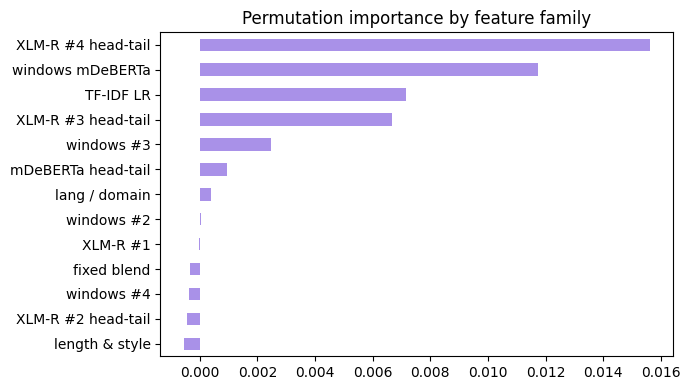

In [ ]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

Xb = build_X(best["blocks"], "val")

cat_mask_b = np.array([c in CAT_COLS for c in Xb.columns])
Xv_b = Xb.to_numpy(np.float64)

a_, b_ = next(
    StratifiedGroupKFold(
        2,
        shuffle=True,
        random_state=SEED,
    ).split(Xv_b, y_val, groups_val)
)

m_b = new_stacker(cat_mask_b).fit(Xv_b[a_], y_val[a_])

base_score = fast_macro_f1(
    y_val[b_],
    m_b.predict(Xv_b[b_]),
)

pi = permutation_importance(
    m_b,
    Xv_b[b_],
    y_val[b_],
    n_repeats=3,
    random_state=SEED,
    scoring=lambda est, X, y: fast_macro_f1(y, est.predict(X)),
)

imp = pd.Series(
    pi.importances_mean,
    index=Xb.columns,
).sort_values(ascending=False)


def family(c):
    for pre, fam in [
        ("tfidf", "TF-IDF LR"),
        ("blend", "fixed blend"),
        ("x1", "XLM-R #1"),
        ("x2", "XLM-R #2 head-tail"),
        ("x3", "XLM-R #3 head-tail"),
        ("x4", "XLM-R #4 head-tail"),
        ("m1", "mDeBERTa head-tail"),
        ("w3_", "windows #3"),
        ("w4_", "windows #4"),
        ("wm_", "windows mDeBERTa"),
        ("w_", "windows #2"),
    ]:
        if c.startswith(pre):
            return fam

    return "lang / domain" if c in ("lang", "domain") else "length & style"


fam_imp = imp.groupby(
    imp.index.map(family)
).sum().sort_values(ascending=False)

print(f"Held-out macro-F1 of this HGB stacker: {base_score:.5f}")

display(imp.head(15).round(5).to_frame("macro-F1 drop"))
display(fam_imp.round(5).to_frame("summed macro-F1 drop"))

fam_imp[::-1].plot.barh(
    figsize=(7, 4),
    color="#A991E8",
    title="Permutation importance by feature family",
)

plt.tight_layout()
plt.show()

In [ ]:
rows = []

for d in sorted(val_df["domain"].unique()):
    mk = (val_df["domain"] == d).to_numpy()

    rows.append({
        "domain": d,
        "n": int(mk.sum()),
        "reference": fast_macro_f1(
            y_val[mk],
            ref_probs[mk].argmax(1),
        ),
        "final stack": fast_macro_f1(
            y_val[mk],
            pred_best[mk],
        ),
    })

dom_tbl = pd.DataFrame(rows)
dom_tbl["gain"] = dom_tbl["final stack"] - dom_tbl["reference"]

display(dom_tbl.round(4))

lens = pd.cut(
    val_df["text"].str.split().str.len(),
    [0, 256, 512, 1024, np.inf],
    labels=["<=256", "257-512", "513-1024", ">1024"],
)

display(
    pd.DataFrame([
        {
            "length": l,
            "n": int((lens == l).sum()),
            "reference": fast_macro_f1(
                y_val[(lens == l).to_numpy()],
                ref_probs[(lens == l).to_numpy()].argmax(1),
            ),
            "final stack": fast_macro_f1(
                y_val[(lens == l).to_numpy()],
                pred_best[(lens == l).to_numpy()],
            ),
        }
        for l in lens.cat.categories
    ]).round(4)
)

,domain,n,reference,final stack,gain
0,arxiv_papers,2979,0.7843,0.9508,0.1665
1,blog_authorship_corpus,8053,0.8222,0.9033,0.0811
2,bundestag,10529,0.9367,0.9721,0.0354
3,cnn_news,8987,0.9433,0.9901,0.0468
4,euro_court_cases,5531,0.9338,0.9678,0.0340
5,gutenberg,1455,0.8113,0.8926,0.0813
6,house_of_commons,6555,0.9268,0.9836,0.0568
7,student_essays,10942,0.9260,0.9752,0.0492


,length,n,reference,final stack
0,<=256,12587,0.8724,0.9373
1,257-512,18432,0.9300,0.9723
2,513-1024,19138,0.9364,0.9786
3,>1024,4874,0.9080,0.9682


## 7. Optional: submit to Kaggle

In [ ]:
if SUBMIT:
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggle_token").strip()

    msg = (
        f"{best_name}, "
        f"blend w={best['w_hgb']}, "
        f"bias={bias_best.tolist()}, "
        f"OOF fold-0 macro-F1={best['oof_macro_f1']:.5f}"
    )

    subprocess.run(
        [
            "kaggle",
            "competitions",
            "submit",
            "-c",
            COMPETITION,
            "-f",
            str(path_best),
            "-m",
            msg,
        ],
        check=True,
    )
else:
    print(
        "SUBMIT = False. Selected file:",
        path_best,
        "| runner-up:",
        path_second,
    )

SUBMIT = False. Selected file: /content/drive/MyDrive/UCU_AI_HW3/submission_final3_stack_+m1.csv | runner-up: /content/drive/MyDrive/UCU_AI_HW3/submission_final3_stack_+x4_nobias.csv
